# 20 · Encoder–Decoder: 보고, 한 칸씩 이어 쓰기

**이번 질문:** 입력 기호열을 읽은 뒤 같은 순서로 출력하려면, decoder는 원문과 자기가 이미 쓴 기호 중 어디를 읽어야 할까요? 학습 때 정답을 보여 주면서 미래 정답은 어떻게 가릴까요?

09번은 고정 길이 4토큰의 결과를 한 번에 예측했습니다. 이번에는 가변 길이의 source와 target을 분리하고, cross-attention으로 원문을 읽으며 한 토큰씩 이어 씁니다.

네 기호 A·B·C·D로 된 길이 1–4의 문자열을 복사하는 작은 과제를 사용합니다. 입력을 기억으로 바꾸는 encoder와 다음 토큰을 계산하는 decoder를 분리하고, 가중치·embedding·attention·손실·갱신을 모두 NumPy로 구현합니다. 학습 후에는 정답 prefix 없이 BOS 하나에서 실제로 생성합니다.

- 준비물: [00](../00_기초/00_math_to_numpy.ipynb)의 축·행렬 곱, [01](../00_기초/01_gradients_and_learning.ipynb)의 중심차분, [02](../00_기초/02_probability_and_losses.ipynb)의 CE, [04](../00_기초/04_optimizers.ipynb)의 Adam, [08](../01_아키텍처/08_attention.ipynb)의 Q·K·V, [09](../01_아키텍처/09_transformer.ipynb)의 residual 블록입니다.
- 도착점: 토큰 이동 → 안전한 마스크 → encoder–decoder 전체 미분 → valid target 손실 → held-out 자유 생성입니다.
- 다음 연결: [19 ViT](19_vit.ipynb)는 이미지 패치를 토큰으로 바꾸고, [21 집합·그래프 attention](21_sets_graph_attention.ipynb)은 순서·이웃 관계가 어떤 mask와 위치 정보를 요구하는지 바꿔 봅니다.

> **용어** · **encoder**는 입력 전체를 읽어 기억 배열을 만드는 함수입니다. **decoder**는 그 기억과 이미 주어진 출력 앞부분으로 다음 기호의 점수를 만드는 함수입니다. **토큰(token)**은 모델이 한 번에 읽거나 쓰는 단위이며 여기서는 기호 하나입니다.
>
> **용어** · **prefix**는 이미 주어진 또는 생성한 앞부분입니다. **BOS**는 시작, **EOS**는 종료, **PAD**는 길이를 맞추는 빈칸 기호이며 1절에서 위치를 구분합니다. **logit**은 softmax 전의 어휘별 점수이고, **held-out**은 학습에 쓰지 않고 남겨 둔 평가 문자열을 뜻합니다.

**교육용 축소 구조입니다.** encoder·decoder가 각 한 층, attention은 한 head이고 residual을 사용합니다. 원 Transformer의 다중 head, FFN, LayerNorm, dropout은 생략합니다. 여기서는 세 attention 경로의 전체 미분과 실제 생성에 집중하며, 원 논문 모델을 그대로 재현했다고 주장하지 않습니다. [Attention Is All You Need 원문](https://arxiv.org/abs/1706.03762).

> **용어** · **FFN**은 위치마다 적용하는 추가 신경망이고, **LayerNorm**은 특징 축의 중심·크기를 조절하는 층입니다. **dropout**은 학습 중 일부 출력을 무작위로 가리는 연산입니다. 이 세 연산은 이번 축소 모델에 포함하지 않습니다.

### 읽는 법

| 표시 | 뜻 | 읽는 방법 |
|---|---|---|
| 🔑 핵심 | 수식·shape·구현 | 어떤 축을 읽고 합하는지 설명합니다 |
| 🔍 확인 | 그림·검산·실험 해석 | 실제 배열과 주장을 대조합니다 |
| 📎 참고 | 환경·관용구·연결 | 필요할 때 돌아옵니다 |
| ✏️ 연습 | 핵심 한두 줄 채우기 | 작은 손계산으로 검사합니다 |

**이 노트북에서 반드시 가져갈 세 가지**

1. decoder 입력은 `BOS + 정답 앞부분`, target은 `정답 + EOS`입니다. 한 칸 이동과 causal mask를 함께 써야 정답을 미리 읽지 않습니다.
2. cross-attention의 Q는 decoder, K·V는 encoder에서 옵니다. encoder에는 K 경로와 V 경로의 기울기가 **더해져** 돌아갑니다.
3. teacher-forcing 정확도와 자유 생성 정확도는 다릅니다. 자유 생성은 자신의 예측을 다음 입력으로 쓰며, 조기 EOS·미종료까지 정답 길이를 분모로 평가합니다.

| 배열 | shape | 의미 |
|---|---|---|
| source ID / decoder ID / target ID | $(N,S)$ / $(N,T)$ / $(N,T)$ | 정수 기호 번호 |
| $X_s,M$ / $X_t,D,H$ | $(N,S,d)$ / $(N,T,d)$ | 연속 특징·encoder 기억·decoder 상태 |
| encoder / decoder / cross 확률 | $(N,S,S)$ / $(N,T,T)$ / $(N,T,S)$ | 마지막 축의 key들을 읽는 비중 |
| logits | $(N,T,V)$ | 각 위치의 어휘 V개 점수 |

[그림 보조 코드](../../src/utils/seq2seq_plots.py) · [학습 경로](../../docs/CURRICULUM.md) · [글 규칙](../../docs/WRITING.md)

📎 **환경과 표기**

NumPy·Matplotlib·Jupyter만 사용합니다. 이미지가 아닌 기호의 순서 문제이므로 MNIST 대신 정확한 문자열과 mask를 그립니다. 계산은 float64, 용도별 seed는 고정합니다. 실제 자료의 고유 sequence를 train·validation·test에 나눠 같은 문자열이 분할 사이에 겹치지 않게 합니다.

> **코드** · `array[..., None]`은 맨 뒤에 길이 1인 축을 더해 mask를 특징 축으로 펼칩니다. `@`는 마지막 두 축의 행렬 곱이며 앞의 배치 축은 유지합니다. `np.swapaxes(x,-1,-2)`는 마지막 두 축만 바꿉니다. `&`는 두 불리언 조건을 함께 만족하는 칸을 고릅니다.

In [1]:
# 준비 셀: 공통 도구와 이 노트북의 순수 그림 함수를 불러옵니다.
import sys
from pathlib import Path
from itertools import product
from time import perf_counter
import numpy as np
project_root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'src/utils/plotting.py').is_file())
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))
from src.utils import setup_plots, run_check
from src.utils.gradcheck import numerical_gradient, rel_error
from src.utils.seq2seq_plots import (
    plot_teacher_shift, plot_attention_masks, plot_encoder_decoder_flow,
    plot_masked_loss, plot_generation_protocol, plot_sequence_history, plot_generated_examples,
)
setup_plots()
PAD, BOS, EOS = 0, 1, 2
TOKEN_NAMES = ["PAD", "BOS", "EOS", "A", "B", "C", "D"]
VOCAB_SIZE = len(TOKEN_NAMES)
print("NumPy", np.__version__, "· 어휘", TOKEN_NAMES)

NumPy 2.4.6 · 어휘 ['PAD', 'BOS', 'EOS', 'A', 'B', 'C', 'D']


## 🔑 1. 정답을 한 칸 옮기고 끝을 표시하기

**이 절에서 가져갈 것:** source·decoder 입력·target을 따로 만들고, 서로 다른 길이를 PAD와 valid mask로 다룹니다.

`A B`를 읽어 `A B`를 쓰는 상황을 생각해 봅시다. 첫 출력 A를 예측할 때 decoder 입력에 A를 바로 넣으면 복사를 배운 것이 아니라 정답을 읽은 셈입니다. 시작 기호를 넣고 정답을 한 칸 오른쪽으로 옮깁니다.

> **용어**
>
> - **BOS(begin of sequence)**는 출력 시작용 기호입니다. 첫 decoder 입력이며 target에는 넣지 않습니다.
> - **EOS(end of sequence)**는 문자열이 끝났다는 기호입니다. 실제로 예측하고 학습·평가에 포함합니다.
> - **PAD(padding)**는 길이를 맞추는 빈칸입니다. 읽을 key와 target 손실에서 제외합니다.
> - **teacher forcing**은 학습 때 decoder에 자신의 예측 대신 정답의 앞부분을 주는 방식입니다.

$$\text{source}=[A,B,EOS,PAD],\quad\text{decoder input}=[BOS,A,B,PAD],$$
$$\text{target}=[A,B,EOS,PAD],\quad \text{valid target}=[1,1,1,0].$$

source는 끝까지 함께 읽어도 되지만, decoder 위치 $t$는 자기 입력의 $0,\dots,t$까지만 읽습니다. 위치 $t$의 decoder 입력은 이전 정답 $y_{t-1}$이고, 같은 위치의 target은 다음 정답 $y_t$입니다. 마지막 유효 위치에서도 EOS를 예측합니다.

In [2]:
# 그림용 직접 계산: ID 3=A, 4=B이며 마지막 열은 길이 맞춤입니다.
shift_source = np.array([3, 4, EOS, PAD])
shift_decoder = np.array([BOS, 3, 4, PAD])
shift_target = np.array([3, 4, EOS, PAD])
shift_valid = shift_target != PAD
shift_source_names = [TOKEN_NAMES[i] for i in shift_source]
shift_decoder_names = [TOKEN_NAMES[i] for i in shift_decoder]
shift_target_names = [TOKEN_NAMES[i] for i in shift_target]

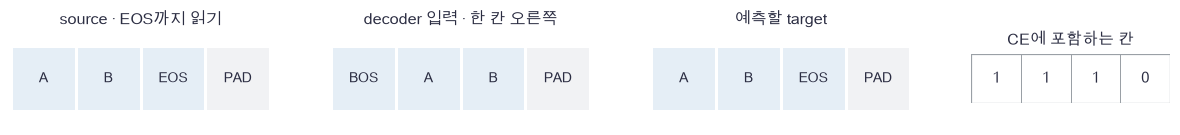

In [3]:
plot_teacher_shift(shift_source_names, shift_decoder_names, shift_target_names, shift_valid.astype(int))

🔍 **그림 확인**

decoder 입력의 B 위치가 EOS를 예측합니다. PAD는 네 번째 클래스 정답이 아니라 손실에 포함하지 않는 자리입니다. 빈 문자열을 받더라도 source는 EOS, decoder 입력은 BOS, target은 EOS가 되어 종료를 배울 수 있습니다. 실제 학습 자료는 길이 1–4를 씁니다.

> **코드** · `list(sequence)`는 튜플을 수정 가능한 목록으로 바꿉니다. `np.full((N,L), PAD)`는 모든 칸을 PAD로 채웁니다. `zip`은 여러 목록의 같은 순서 항목을 묶습니다. `[TOKEN_NAMES[i] for i in ids]`는 ID별 표시 이름을 모으는 목록 내포입니다.

In [4]:
# 쓰는 것: PAD, BOS, EOS (준비 셀)
def pack_sequences(sequences, width=None):
    """복사 과제의 source·shifted decoder·target 및 valid mask를 만듭니다."""
    needed = max(len(sequence) + 1 for sequence in sequences)
    width = needed if width is None else width
    assert width >= needed, "EOS까지 넣을 충분한 폭이 필요합니다"
    source = np.full((len(sequences), width), PAD, dtype=int)
    decoder = np.full_like(source, PAD)
    target = np.full_like(source, PAD)
    for n, sequence in enumerate(sequences):
        tokens = list(sequence)
        length = len(tokens) + 1
        source[n, :length] = tokens + [EOS]
        decoder[n, :length] = [BOS] + tokens
        target[n, :length] = tokens + [EOS]
    return source, decoder, target, source != PAD, target != PAD

In [5]:
# 쓰는 것: shift_source, shift_decoder, shift_target (1절 손계산), EOS, BOS (준비 셀)
packed_source, packed_decoder, packed_target, packed_source_keep, packed_target_keep = pack_sequences([(3, 4)], width=4)
np.testing.assert_array_equal(packed_source[0], shift_source)  # 검산: source에는 EOS 뒤 PAD를 넣습니다.
np.testing.assert_array_equal(packed_decoder[0], shift_decoder)  # 검산: decoder는 BOS로 시작해 정답보다 한 칸 늦습니다.
np.testing.assert_array_equal(packed_target[0], shift_target)  # 검산: target은 EOS를 포함합니다.
empty_pack = pack_sequences([()])
np.testing.assert_array_equal(empty_pack[0], [[EOS]])  # 검산: 빈 원문도 종료 기호를 갖습니다.
np.testing.assert_array_equal(empty_pack[1], [[BOS]])  # 검산: 빈 출력의 첫 입력은 BOS입니다.
print("shift·길이·빈 문자열 규약 검산 통과")

shift·길이·빈 문자열 규약 검산 통과


### ✏️ 연습 1 · decoder 입력과 target 나누기

연습은 코딩 테스트처럼 **함수 뼈대가 미리 있고 핵심 한두 줄만 비어 있습니다.** `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓴 뒤, 셀을 실행하고 바로 아래 검사 셀을 실행하세요. 아직 채우지 않았으면 안내문만 나오고, 값이 다르면 "손계산과 다릅니다"가 나옵니다. 막히면 그 아래 "정답 보기"를 펼칩니다.

기호 목록 `tokens`와 BOS·EOS 번호를 받습니다. 시작을 넣은 decoder 입력과 끝을 넣은 target을 두 줄로 만드세요. padding은 없는 한 표본입니다.

In [6]:
def exercise_shift(tokens, bos, eos):
    """정답 목록을 한 칸 옮겨 teacher-forcing 입력과 target을 만듭니다."""
    raise NotImplementedError
    return decoder, target

In [7]:
def check_shift(candidate):
    """기호 두 개와 빈 문자열의 시작·종료 위치를 검사합니다."""
    decoder, target = candidate([3, 4], 1, 2)
    np.testing.assert_array_equal(decoder, [1, 3, 4])  # 검산: BOS 다음에 원래 기호를 놓습니다.
    np.testing.assert_array_equal(target, [3, 4, 2])  # 검산: 끝의 EOS도 target입니다.
    np.testing.assert_array_equal(candidate([], 1, 2), [[1], [2]])  # 검산: 빈 문자열도 EOS 한 칸을 예측합니다.
run_check(check_shift, exercise_shift)

☐ exercise_shift: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
decoder = [bos] + list(tokens)
target = list(tokens) + [eos]
```

</details>

## 🔑 2. 읽어도 되는 칸만 attention으로 합하기

**이 절에서 가져갈 것:** source padding·decoder causal/key padding mask를 결합하고, 전부 막힌 행까지 안전한 attention forward·backward를 구현합니다.

decoder가 첫 A를 예측하는 순간 뒤의 B와 EOS를 읽으면 안 됩니다. 반대로 원문에서 어느 기호를 참고할지는 출력 위치마다 달라질 수 있습니다. 읽을 수 있는 칸을 먼저 정하고, 그 안에서만 확률을 나눕니다.

> **용어** · **self-attention**은 Q·K·V를 같은 배열에서 만듭니다. **cross-attention**은 질문 Q를 decoder에서, 찾아볼 K와 가져올 V를 encoder 기억에서 만듭니다. **causal mask**는 미래의 key를 막는 삼각형 규칙입니다.

$$Q=X_qW_Q,\quad K=X_kW_K,\quad V=X_kW_V,\quad S=QK^T/\sqrt d,\quad A=\operatorname{maskedsoftmax}(S),\quad O=(AV)W_O.$$

$X_q$가 $(N,T,d)$, $X_k$가 $(N,S,d)$이면 $A$는 $(N,T,S)$입니다. 마지막 축 S에서 읽을 key의 비중을 나눕니다. mask는 `True`인 곳만 허용합니다.

$$M_e[n,i,j]=s_{ni}s_{nj},\quad M_d[n,i,j]=t_{ni}t_{nj}1[j\le i],\quad M_c[n,i,j]=t_{ni}s_{nj}.$$

$s,t$는 source·decoder의 유효 위치입니다. 여기서는 key뿐 아니라 PAD query 행도 막습니다. **허용 key가 하나도 없는 행은 확률을 모두 0, attention 출력도 0**으로 정의합니다. 통상 softmax의 “행 합 1”을 이 경우에는 요구하지 않습니다. 음의 무한대를 전부 넣고 softmax를 그대로 실행하면 `-inf - (-inf)` 때문에 NaN이 생길 수 있어 별도로 처리합니다.

In [8]:
# 그림의 마지막 query는 전부 막혀 있습니다. 출력도 0이 됩니다.
mask_scores = np.array([[0., 1., 2.], [2., 0., 1.], [1., 2., 0.]])
mask_allowed = np.array([[True, False, False], [True, True, False], [False, False, False]])
mask_safe_scores = np.where(mask_allowed, mask_scores, -np.inf)
mask_maximum = np.max(mask_safe_scores, axis=1, keepdims=True)
mask_maximum = np.where(np.any(mask_allowed, axis=1, keepdims=True), mask_maximum, 0.0)
mask_exp = np.exp(np.where(mask_allowed, mask_scores - mask_maximum, -np.inf))
mask_sum = np.sum(mask_exp, axis=1, keepdims=True)
mask_probability = np.divide(mask_exp, mask_sum, out=np.zeros_like(mask_exp), where=mask_sum > 0)
mask_values = np.array([[1., 0.], [0., 2.], [3., 3.]])
mask_output = mask_probability @ mask_values

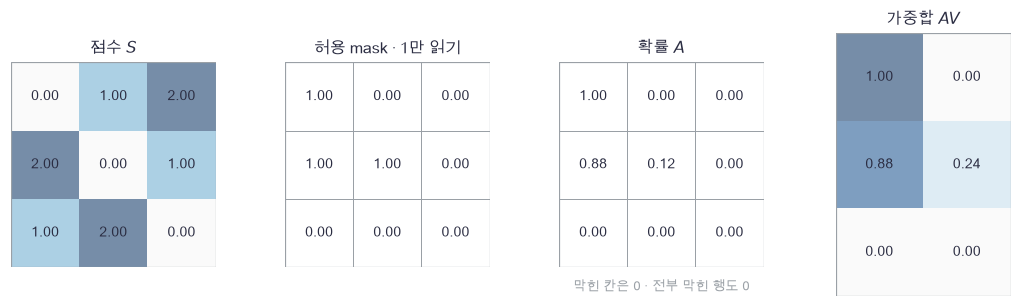

In [9]:
plot_attention_masks(mask_scores, mask_allowed.astype(int), mask_probability, mask_output)

🔍 **그림 확인과 미분**

첫 행은 첫 key만 읽어 확률이 1입니다. 둘째 행은 앞 두 key 사이에 비중을 나누며 셋째 key는 확률 0입니다. 마지막 행은 어디도 읽지 않아 출력 0입니다. mask는 학습 파라미터가 아니라 고정된 경로 선택입니다.

$C=AV$, 출력 기울기를 $G$라 하면

$$dW_O=C^TG,\quad dC=GW_O^T,\quad dA=dCV^T,\quad dV=A^TdC,$$
$$dS=A\odot\left(dA-\sum_j A\odot dA\right),\quad dQ=dSK/\sqrt d,\quad dK=dS^TQ/\sqrt d.$$

가중치 기울기는 배치·시간 축을 모두 합합니다. 예를 들어 $dW_Q=\sum_{n,t}X_{q,nt}^T dQ_{nt}$입니다. 입력에는

$$dX_q=dQW_Q^T,\qquad dX_k=dKW_K^T+dVW_V^T$$

가 돌아갑니다. cross-attention의 encoder는 두 항을 받아야 합니다. 마스크가 0인 칸은 A=0이므로 $dS$도 정확히 0이고, 전부 막힌 행 역시 입력 경로의 기여가 0입니다.

> **코드** · `np.where(mask, a, b)`는 칸마다 a 또는 b를 고릅니다. `np.divide(..., out=0배열, where=분모>0)`는 분모가 양수인 곳만 나누고 나머지를 0으로 남깁니다. `reshape(-1,d)`는 배치와 시간 축을 한 행 축으로 합쳐 가중치 기울기의 합을 행렬 곱으로 계산하게 합니다.

In [10]:
def masked_softmax(scores, allowed):
    """마지막 축의 허용 key만 정규화하며 전부 막힌 query 행은 0으로 둡니다."""
    safe_scores = np.where(allowed, scores, -np.inf)
    any_key = np.any(allowed, axis=-1, keepdims=True)
    maximum = np.max(safe_scores, axis=-1, keepdims=True)
    maximum = np.where(any_key, maximum, 0.0)
    exponentials = np.exp(np.where(allowed, scores - maximum, -np.inf))
    denominator = np.sum(exponentials, axis=-1, keepdims=True)
    return np.divide(exponentials, denominator, out=np.zeros_like(exponentials), where=denominator > 0)

In [11]:
def softmax_backward(gradient, probability):
    """각 query의 softmax를 미분하며 mask로 0인 확률의 경로도 0으로 둡니다."""
    weighted = np.sum(gradient * probability, axis=-1, keepdims=True)
    return probability * (gradient - weighted)

In [12]:
def attention_masks(source_keep, target_keep):
    """encoder self·decoder causal self·cross의 query/key 허용 mask를 만듭니다."""
    length = target_keep.shape[1]
    causal = np.arange(length)[None, :] <= np.arange(length)[:, None]
    encoder = source_keep[:, :, None] & source_keep[:, None, :]
    decoder = target_keep[:, :, None] & target_keep[:, None, :] & causal[None, :, :]
    cross = target_keep[:, :, None] & source_keep[:, None, :]
    return encoder, decoder, cross

In [13]:
# 쓰는 것: masked_softmax (2절)
def attention_forward(xq, xk, allowed, params, prefix):
    """한 head의 Q/K/V 투영·masked attention·출력 투영을 계산합니다."""
    wq, wk, wv, wo = [params[prefix + suffix] for suffix in ("q", "k", "v", "o")]
    q, k, v = xq @ wq, xk @ wk, xk @ wv
    scores = q @ np.swapaxes(k, -1, -2) / np.sqrt(q.shape[-1])
    probability = masked_softmax(scores, allowed)
    context = probability @ v
    output = context @ wo
    cache = (xq, xk, q, k, v, probability, context, wq, wk, wv, wo, prefix)
    return output, cache

In [14]:
# 쓰는 것: softmax_backward (2절)
def attention_backward(gradient, cache):
    """Q 입력과 공유 K/V 입력의 기여를 분리해 전체 attention을 미분합니다."""
    xq, xk, q, k, v, probability, context, wq, wk, wv, wo, prefix = cache
    dimension = q.shape[-1]
    # 1) 출력 투영과 값의 가중합을 미분합니다.
    gradients = {prefix + "o": context.reshape(-1, dimension).T @ gradient.reshape(-1, dimension)}
    dcontext = gradient @ wo.T
    dprobability = dcontext @ np.swapaxes(v, -1, -2)
    dv = np.swapaxes(probability, -1, -2) @ dcontext
    # 2) softmax와 Q·K 점수 경로를 거슬러 갑니다.
    dscores = softmax_backward(dprobability, probability)
    dq = dscores @ k / np.sqrt(dimension)
    dk = np.swapaxes(dscores, -1, -2) @ q / np.sqrt(dimension)
    gradients[prefix + "q"] = xq.reshape(-1, dimension).T @ dq.reshape(-1, dimension)
    gradients[prefix + "k"] = xk.reshape(-1, dimension).T @ dk.reshape(-1, dimension)
    gradients[prefix + "v"] = xk.reshape(-1, dimension).T @ dv.reshape(-1, dimension)
    # 3) K와 V가 같은 encoder 기억에서 왔으므로 두 기여를 더합니다.
    dxq = dq @ wq.T
    dxk = dk @ wk.T + dv @ wv.T
    return dxq, dxk, gradients

In [15]:
# 쓰는 것: mask_scores, mask_allowed, mask_probability (2절 그림), masked_softmax, softmax_backward (2절)
actual_mask_probability = masked_softmax(mask_scores, mask_allowed)
np.testing.assert_allclose(actual_mask_probability, mask_probability)  # 검산: 구현은 그림의 직접 계산과 같습니다.
np.testing.assert_array_equal(actual_mask_probability[~mask_allowed], 0.)  # 검산: 막힌 칸의 확률은 정확히 0입니다.
mask_dscores = softmax_backward(np.arange(9.).reshape(3, 3), actual_mask_probability)
np.testing.assert_array_equal(mask_dscores[~mask_allowed], 0.)  # 검산: 막힌 score의 기울기도 정확히 0입니다.
np.testing.assert_array_equal(actual_mask_probability[-1], 0.)  # 검산: 전부 막힌 query에는 확률 질량을 주지 않습니다.
print("mask 확률·기울기와 all-masked 행 규약 검산 통과")

mask 확률·기울기와 all-masked 행 규약 검산 통과


In [16]:
# 쓰는 것: attention_forward, attention_backward (2절)
attention_probe_rng = np.random.default_rng(201)
attention_probe_q = attention_probe_rng.normal(size=(1, 2, 2))
attention_probe_k = attention_probe_rng.normal(size=(1, 3, 2))
attention_probe_params = {"p_" + name: np.eye(2) for name in ("q", "k", "v", "o")}
attention_probe_mask = np.array([[[True, False, False], [False, False, False]]])
attention_probe_output, attention_probe_cache = attention_forward(attention_probe_q, attention_probe_k, attention_probe_mask, attention_probe_params, "p_")
probe_dq, probe_dk, _ = attention_backward(np.ones_like(attention_probe_output), attention_probe_cache)
np.testing.assert_array_equal(attention_probe_output[:, 1], 0.)  # 검산: all-masked query의 attention 출력은 0입니다.
np.testing.assert_array_equal(probe_dq[:, 1], 0.)  # 검산: all-masked query 입력 기울기는 0입니다.
np.testing.assert_array_equal(probe_dk[:, 1:], 0.)  # 검산: 한 번도 읽지 않은 K/V 위치에는 기울기가 없습니다.
print("query·key 입력까지 막힌 경로의 0 기울기 확인")

query·key 입력까지 막힌 경로의 0 기울기 확인


### ✏️ 연습 2 · causal과 padding 조건을 함께 쓰기

`keep`은 `(N,T)`의 유효 decoder 위치입니다. `causal`은 아래에서 준비했습니다. query·key가 둘 다 유효하고 미래가 아닌 칸만 허용하는 한 줄을 채우세요.

In [17]:
def exercise_decoder_mask(keep):
    """미래와 PAD query/key를 함께 막는 (N,T,T) mask를 만듭니다."""
    length = keep.shape[1]
    causal = np.arange(length)[None, :] <= np.arange(length)[:, None]
    raise NotImplementedError
    return allowed

In [18]:
def check_decoder_mask(candidate):
    """두 유효 위치와 마지막 PAD의 허용 관계를 손으로 검사합니다."""
    actual = candidate(np.array([[True, True, False]]))
    expected = [[[True, False, False], [True, True, False], [False, False, False]]]
    np.testing.assert_array_equal(actual, expected)  # 검산: PAD 행·열과 미래 칸은 모두 막힙니다.
run_check(check_decoder_mask, exercise_decoder_mask)

☐ exercise_decoder_mask: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
allowed = keep[:, :, None] & keep[:, None, :] & causal[None, :, :]
```

</details>

## 🔑 3. encoder의 기억과 decoder의 질문 연결하기

**이 절에서 가져갈 것:** 토큰 lookup·고정 위치·세 attention·residual을 연결하고, 중복 토큰의 embedding 기울기와 encoder의 여러 경로를 합합니다.

원문의 A를 기억하는 위치와 decoder가 첫 글자를 쓰는 위치는 서로 다른 배열에 있습니다. encoder는 원문 전체를 먼저 읽고, decoder는 자기 앞부분으로 질문을 만든 뒤 그 기억을 다시 읽습니다.

> **용어** · **embedding**은 정수 ID마다 학습 가능한 특징 벡터 한 행을 꺼내는 표입니다. **위치 부호화(positional encoding)**는 같은 기호도 어느 위치인지 구별하도록 더하는 벡터입니다. **residual**은 층의 출력에 원래 입력을 더하는 경로입니다.

source·target embedding 표 $E_s,E_t\in\mathbb R^{V\times d}$는 서로 별개입니다. 고정된 위치 벡터는

$$P_{t,2j}=\sin(t/10000^{2j/d}),\qquad P_{t,2j+1}=\cos(t/10000^{2j/d})$$

이고, $X_s=E_s[\mathrm{source}]+P$, $X_t=E_t[\mathrm{decoder}]+P$로 만듭니다. 여기서는 짝수 d를 사용하고 P는 학습하지 않습니다. 학습 가능한 위치 표를 쓰는 방법도 있지만 그 경우 위치 표의 기울기와 학습하지 않은 위치 처리 규칙을 추가해야 합니다. 고정 P가 더 긴 길이에도 계산 가능하다는 사실만으로 길이 일반화가 보장되지는 않습니다.

$$M=X_s+\operatorname{Attn}_e(X_s,X_s),\quad D=X_t+\operatorname{Attn}_d(X_t,X_t),$$
$$H=D+\operatorname{Attn}_c(D,M),\qquad Z=HW_{out}+b_{out}.$$

세 attention은 별도 가중치를 사용합니다. source는 양방향 self, decoder는 causal self, 마지막은 cross입니다. 모든 단계에서 PAD query 특징을 0으로 유지하고 마지막 logit도 유효 query에만 남깁니다. 다음 그림은 $d=2$, attention 투영 행렬이 항등행렬인 손계산 흐름입니다. 학습된 표현이나 생성 결과가 아닙니다.

In [19]:
# 쓰는 것: masked_softmax (2절). 그림에서는 Q/K/V/출력 투영을 모두 항등으로 둡니다.
graph_source = np.array([[1., 0.], [0., 1.], [1., 1.]])
graph_target = np.array([[0., 0.], [1., 0.], [0., 1.]])
graph_all = np.ones((3, 3), dtype=bool)
graph_causal = np.arange(3)[None, :] <= np.arange(3)[:, None]
graph_encoder_weights = masked_softmax(graph_source @ graph_source.T / np.sqrt(2), graph_all)
graph_memory = graph_source + graph_encoder_weights @ graph_source
graph_decoder_weights = masked_softmax(graph_target @ graph_target.T / np.sqrt(2), graph_causal)
graph_decoder = graph_target + graph_decoder_weights @ graph_target
graph_cross_weights = masked_softmax(graph_decoder @ graph_memory.T / np.sqrt(2), graph_all)
graph_hidden = graph_decoder + graph_cross_weights @ graph_memory
graph_output_matrix = np.array([[1., 0., -1.], [0., 1., -1.]])
graph_logits = graph_hidden @ graph_output_matrix

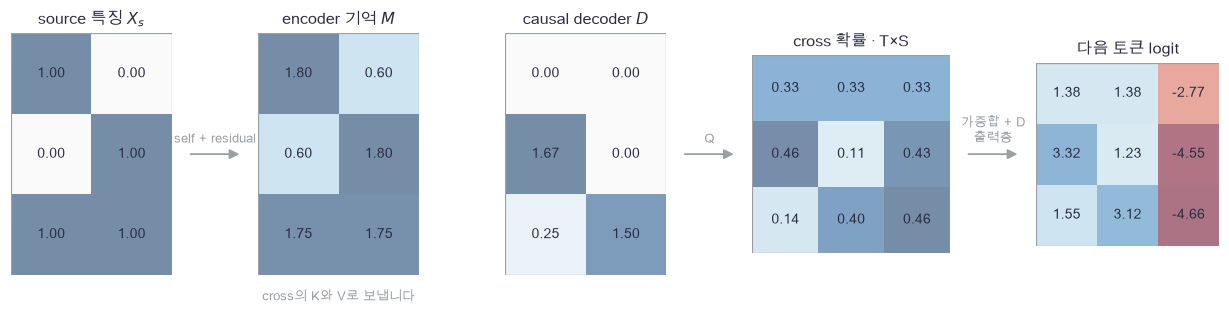

In [20]:
plot_encoder_decoder_flow(graph_source, graph_memory, graph_decoder, graph_cross_weights, graph_logits)

🔍 **그림 확인과 두 종류의 누적**

cross 확률의 행은 출력 위치이고 열은 원문 위치입니다. decoder 질문 D와 encoder 기억 M의 역할이 다릅니다. 역전파에서는 cross의 K·V 기여를 먼저 합쳐 $dM$을 만들고, encoder의 residual과 self-attention의 Q·K·V 기여를 다시 합칩니다.

$$dD=dH+dD_{cross},\quad dX_t=dD+dX_{t,Q}+dX_{t,K}+dX_{t,V},$$
$$dM=dM_K+dM_V,\quad dX_s=dM+dX_{s,Q}+dX_{s,K}+dX_{s,V}.$$

같은 토큰 A가 한 배치에서 여러 번 나오면 embedding 표의 같은 행을 여러 번 읽습니다. 그 행의 기울기는 각 위치 기여의 **합**입니다. 단순한 중복 인덱스 대입이 아니라 누적 연산을 사용합니다.

> **코드** · `np.add.at(table_gradient, token_ids, contribution)`은 같은 ID가 여러 번 있어도 그 행에 모든 기여를 더합니다. `prefix + "q"`처럼 이름을 붙인 사전 키로 encoder(`e_`), decoder(`d_`), cross(`c_`)의 별도 가중치를 구분합니다. `dict.update`는 서로 다른 이름의 기울기 사전을 합칩니다.

In [21]:
def positional_encoding(length, dimension):
    """학습하지 않는 sin/cos 위치 벡터 (length,dimension)를 만듭니다."""
    assert dimension % 2 == 0, "이 구현의 특징 차원은 짝수여야 합니다"
    positions = np.arange(length)[:, None]
    rates = 10000.0 ** (-np.arange(0, dimension, 2) / dimension)
    encoding = np.zeros((length, dimension))
    encoding[:, 0::2] = np.sin(positions * rates)
    encoding[:, 1::2] = np.cos(positions * rates)
    return encoding

In [22]:
# 쓰는 것: positional_encoding (3절)
def embedding_forward(token_ids, table, keep):
    """ID의 표 행과 고정 위치를 더하고 PAD 위치를 0으로 만듭니다."""
    positions = positional_encoding(token_ids.shape[1], table.shape[1])
    features = (table[token_ids] + positions[None, :, :]) * keep[..., None]
    return features, (token_ids, keep, table.shape)

In [23]:
def embedding_backward(gradient, cache):
    """동일 토큰의 반복 위치를 모두 같은 embedding 행에 누적합니다."""
    token_ids, keep, table_shape = cache
    table_gradient = np.zeros(table_shape)
    np.add.at(table_gradient, token_ids, gradient * keep[..., None])
    return table_gradient

In [24]:
def init_sequence_model(dimension=16, vocab_size=7, seed=202):
    """두 embedding·세 attention·출력 분류기의 독립 파라미터를 만듭니다."""
    rng = np.random.default_rng(seed)
    params = {
        "src_embedding": rng.normal(0, 0.2, (vocab_size, dimension)),
        "tgt_embedding": rng.normal(0, 0.2, (vocab_size, dimension)),
    }
    for prefix in ("e_", "d_", "c_"):
        for suffix in ("q", "k", "v", "o"):
            params[prefix + suffix] = rng.normal(0, 0.5 / np.sqrt(dimension), (dimension, dimension))
    params["out_w"] = rng.normal(0, 1 / np.sqrt(dimension), (dimension, vocab_size))
    params["out_b"] = np.zeros(vocab_size)
    return params

In [25]:
# 쓰는 것: attention_forward (2절)
def encoder_forward(source_features, source_keep, params):
    """source self-attention과 residual로 기억 (N,S,d)을 계산합니다."""
    source = source_features * source_keep[..., None]
    allowed = source_keep[:, :, None] & source_keep[:, None, :]
    attended, attention_cache = attention_forward(source, source, allowed, params, "e_")
    memory = (source + attended) * source_keep[..., None]
    return memory, (attention_cache, source_keep)

In [26]:
# 쓰는 것: attention_backward (2절)
def encoder_backward(dmemory, cache):
    """cross에서 온 기억 기울기를 residual·self Q/K/V 경로로 합칩니다."""
    attention_cache, source_keep = cache
    gradient = dmemory * source_keep[..., None]
    dquery, dkey_value, gradients = attention_backward(gradient, attention_cache)
    dsource = (gradient + dquery + dkey_value) * source_keep[..., None]
    return dsource, gradients

In [27]:
# 쓰는 것: attention_masks, attention_forward (2절)
def decoder_forward(target_features, memory, source_keep, target_keep, params):
    """causal self → cross와 두 residual을 거쳐 다음 토큰 점수를 냅니다."""
    target = target_features * target_keep[..., None]
    _, self_mask, cross_mask = attention_masks(source_keep, target_keep)
    self_output, self_cache = attention_forward(target, target, self_mask, params, "d_")
    decoder = (target + self_output) * target_keep[..., None]
    cross_output, cross_cache = attention_forward(decoder, memory, cross_mask, params, "c_")
    hidden = (decoder + cross_output) * target_keep[..., None]
    logits = (hidden @ params["out_w"] + params["out_b"]) * target_keep[..., None]
    cache = (hidden, self_cache, cross_cache, target_keep, params["out_w"])
    return logits, cache

In [28]:
# 쓰는 것: attention_backward (2절)
def decoder_backward(dlogits, cache):
    """출력에서 decoder 입력과 encoder 기억으로 기울기를 나누어 돌려줍니다."""
    hidden, self_cache, cross_cache, target_keep, output_weights = cache
    # 1) 출력 분류기를 미분합니다. PAD query 기울기는 0으로 고정합니다.
    gradient = dlogits * target_keep[..., None]
    gradients = {
        "out_w": hidden.reshape(-1, hidden.shape[-1]).T @ gradient.reshape(-1, gradient.shape[-1]),
        "out_b": np.sum(gradient, axis=(0, 1)),
    }
    dhidden = (gradient @ output_weights.T) * target_keep[..., None]
    # 2) cross의 K/V 기여는 attention_backward 안에서 encoder 기억으로 더해집니다.
    ddecoder_cross, dmemory, cross_gradients = attention_backward(dhidden, cross_cache)
    ddecoder = (dhidden + ddecoder_cross) * target_keep[..., None]
    gradients.update(cross_gradients)
    # 3) causal self의 세 입력 경로와 residual을 합합니다.
    dquery, dkey_value, self_gradients = attention_backward(ddecoder, self_cache)
    dtarget = (ddecoder + dquery + dkey_value) * target_keep[..., None]
    gradients.update(self_gradients)
    return dtarget, dmemory, gradients

In [29]:
# 쓰는 것: encoder_forward, decoder_forward (3절)
def features_forward(source_features, target_features, source_keep, target_keep, params):
    """연속 특징에서 encoder와 decoder를 연결한 전체 forward를 계산합니다."""
    memory, encoder_cache = encoder_forward(source_features, source_keep, params)
    logits, decoder_cache = decoder_forward(target_features, memory, source_keep, target_keep, params)
    return logits, (encoder_cache, decoder_cache)

In [30]:
# 쓰는 것: encoder_backward, decoder_backward (3절)
def features_backward(dlogits, cache):
    """cross 기억 기울기를 encoder까지 전달해 두 연속 입력의 미분을 구합니다."""
    encoder_cache, decoder_cache = cache
    dtarget, dmemory, gradients = decoder_backward(dlogits, decoder_cache)
    dsource, encoder_gradients = encoder_backward(dmemory, encoder_cache)
    gradients.update(encoder_gradients)
    return dsource, dtarget, gradients

In [31]:
# 쓰는 것: embedding_forward, features_forward (3절)
def sequence_forward(source_ids, decoder_ids, source_keep, target_keep, params):
    """정수 ID lookup부터 위치·attention·출력 logit까지 연결합니다."""
    source, source_cache = embedding_forward(source_ids, params["src_embedding"], source_keep)
    target, target_cache = embedding_forward(decoder_ids, params["tgt_embedding"], target_keep)
    logits, features_cache = features_forward(source, target, source_keep, target_keep, params)
    return logits, (features_cache, source_cache, target_cache)

In [32]:
# 쓰는 것: features_backward, embedding_backward (3절)
def sequence_backward(dlogits, cache):
    """연속 특징 기울기를 거쳐 반복 ID의 embedding 표 기울기까지 누적합니다."""
    features_cache, source_cache, target_cache = cache
    dsource, dtarget, gradients = features_backward(dlogits, features_cache)
    gradients["src_embedding"] = embedding_backward(dsource, source_cache)
    gradients["tgt_embedding"] = embedding_backward(dtarget, target_cache)
    return dsource, dtarget, gradients

In [33]:
# 쓰는 것: embedding_forward, embedding_backward (3절), graph_source, graph_target, graph_logits, graph_output_matrix (3절 그림), init_sequence_model, features_forward (3절)
graph_params = init_sequence_model(dimension=2, vocab_size=3)
for prefix in ("e_", "d_", "c_"):
    for suffix in ("q", "k", "v", "o"):
        graph_params[prefix + suffix] = np.eye(2)
graph_params["out_w"] = graph_output_matrix.copy()
graph_keep = np.ones((1, 3), dtype=bool)
graph_actual, _ = features_forward(graph_source[None], graph_target[None], graph_keep, graph_keep, graph_params)
np.testing.assert_allclose(graph_actual[0], graph_logits)  # 검산: 연결 모델은 항등 투영의 손계산 그림과 같습니다.
repeated_ids = np.array([[3, 3, 0]])
repeated_keep = np.array([[True, True, False]])
_, repeated_cache = embedding_forward(repeated_ids, np.zeros((7, 2)), repeated_keep)
repeated_gradient = embedding_backward(np.array([[[1., 2.], [3., 4.], [9., 9.]]]), repeated_cache)
np.testing.assert_array_equal(repeated_gradient[3], [4., 6.])  # 검산: 같은 ID의 1+3, 2+4 기여를 누적합니다.
np.testing.assert_array_equal(repeated_gradient[0], 0.)  # 검산: PAD 위치의 값은 embedding 기울기에 포함하지 않습니다.
print("전체 forward 손계산·중복 embedding 누적 검산 통과")

전체 forward 손계산·중복 embedding 누적 검산 통과


### ✏️ 연습 3 · K와 V가 같은 기억으로 돌아갈 때

`dk`,`dv`는 각각 K·V의 기울기이고 `wk`,`wv`는 투영 가중치입니다. encoder 기억에 돌아갈 두 기여의 합 한 줄을 채우세요.

In [34]:
def exercise_memory_gradient(dk, dv, wk, wv):
    """같은 encoder 기억에서 나온 K와 V의 입력 기울기를 더합니다."""
    raise NotImplementedError
    return dmemory

In [35]:
def check_memory_gradient(candidate):
    """대각 가중치 두 경로의 합을 독립적인 손계산으로 검사합니다."""
    dk = np.array([[[1., 2.]]])
    dv = np.array([[[3., 4.]]])
    result = candidate(dk, dv, np.diag([2., 1.]), np.diag([1., 3.]))
    np.testing.assert_allclose(result, [[[5., 14.]]])  # 검산: [2,2]+[3,12]=[5,14]입니다.
run_check(check_memory_gradient, exercise_memory_gradient)

☐ exercise_memory_gradient: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
dmemory = dk @ wk.T + dv @ wv.T
```

</details>

## 🔑 4. valid target만 평균하고 전체 미분 검산하기

**이 절에서 가져갈 것:** EOS를 포함한 유효 target 수로 CE를 나누고, 모든 파라미터·연속 입력의 미분과 미래·PAD 불변성을 확인합니다.

길이 1인 문자열과 길이 2인 문자열을 한 배치에 넣으면 PAD 개수가 다릅니다. 전체 직사각형의 칸 수로 손실을 나누면 같은 문장도 padding 폭에 따라 기울기 크기가 바뀝니다. 유효한 정답 칸만 분모에 넣습니다.

$$C=\sum_{n,t}m_{nt},\quad L=-\frac1C\sum_{n,t}m_{nt}\log p_{nt,y_{nt}},\quad
 dZ_{ntk}=\frac{m_{nt}}C\left(p_{ntk}-1[k=y_{nt}]\right).$$

$m$은 target valid mask입니다. EOS는 1, PAD는 0입니다. 이 정의는 이미지별 평균 같은 방식과 달리 **각 유효 토큰에 같은 비중**을 줍니다. 더 긴 문자열은 더 많은 학습 토큰을 제공합니다. 유효 target이 하나도 없는 경우 손실 평균은 정의하지 않고 오류로 알립니다. 보통 배치는 빈 문자열이라도 EOS가 있어 $C\ge1$입니다.

log-softmax는 $z-\max(z)-\log\sum\exp(z-\max(z))$로 계산합니다. 확률에 작은 상수를 더해 log를 취하는 방식으로 극단 손실을 잘라내지 않습니다. 아래는 `A EOS PAD`와 `B C EOS`의 다섯 target만 평균하는 그림입니다.

In [36]:
# 쓰는 것: PAD, EOS, VOCAB_SIZE (준비 셀)
loss_targets = np.array([[3, EOS, PAD], [4, 5, EOS]])
loss_valid = loss_targets != PAD
loss_logits = np.zeros((2, 3, VOCAB_SIZE))
loss_logits[0, 0, 3] = np.log(6.)
loss_logits[1, 2, EOS] = np.log(6.)
loss_shifted = loss_logits - np.max(loss_logits, axis=-1, keepdims=True)
loss_log_probability = loss_shifted - np.log(np.sum(np.exp(loss_shifted), axis=-1, keepdims=True))
loss_nll = -loss_log_probability.reshape(-1, VOCAB_SIZE)[np.arange(6), loss_targets.ravel()].reshape(2, 3)
loss_gradient = np.exp(loss_log_probability).reshape(-1, VOCAB_SIZE)
loss_gradient[np.arange(6), loss_targets.ravel()] -= 1
loss_gradient = loss_gradient.reshape(loss_logits.shape) * loss_valid[..., None] / np.sum(loss_valid)

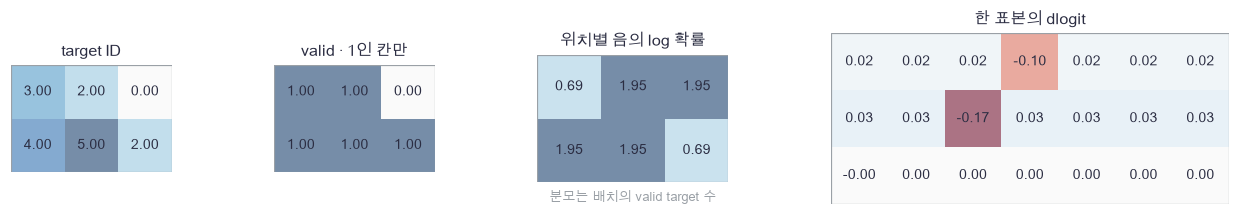

In [37]:
plot_masked_loss(loss_targets, loss_valid.astype(int), loss_nll, loss_gradient[0])

🔍 **그림 확인과 검산의 입력**

PAD 칸에도 점수에서 계산한 음의 log 확률 값은 있지만 손실 합과 분모에 넣지 않습니다. 해당 logit 기울기도 0입니다. 그림의 손실은 $(2\log2+3\log7)/5$입니다.

아래 전체 모델 검사는 두 종류를 구분합니다. 먼저 **학습 가능한 모든 파라미터**를 흔들어 actual CE의 중심차분과 비교합니다. 여기에는 반복 ID를 읽는 두 embedding 표도 포함됩니다. 다음으로 lookup 뒤의 **연속 특징** $X_s,X_t$를 흔들어 입력 기울기를 검사합니다. **정수 토큰 ID를 미분하는 검사가 아닙니다.** 고정된 위치 벡터도 학습 파라미터로 미분하지 않습니다.

> **코드** · `ravel()`은 원소 순서를 유지해 한 줄로 펼칩니다. `log_probs[rows, target]`는 펼친 각 위치에서 정답 클래스 칸을 고릅니다. `np.testing.assert_allclose`는 수치 오차를 허용한 비교이고, mask 때문에 정확히 0이어야 하는 자리에는 `assert_array_equal`을 씁니다.

In [38]:
def masked_cross_entropy(logits, target, valid):
    """EOS 포함 valid target만 평균하는 안정 CE와 logit 기울기를 구합니다."""
    count = int(np.sum(valid))
    assert count > 0, "평균 손실에는 유효 target이 한 개 이상 필요합니다"
    shifted = logits - np.max(logits, axis=-1, keepdims=True)
    log_probability = shifted - np.log(np.sum(np.exp(shifted), axis=-1, keepdims=True))
    flat_log = log_probability.reshape(-1, logits.shape[-1])
    rows = np.arange(target.size)
    selected = flat_log[rows, target.ravel()]
    loss = -np.sum(selected * valid.ravel()) / count
    gradient = np.exp(flat_log)
    gradient[rows, target.ravel()] -= 1
    gradient = gradient.reshape(logits.shape) * valid[..., None] / count
    return float(loss), gradient

In [39]:
# 쓰는 것: loss_logits, loss_targets, loss_valid, loss_gradient (4절 그림)
hand_ce, hand_ce_gradient = masked_cross_entropy(loss_logits, loss_targets, loss_valid)
np.testing.assert_allclose(hand_ce, (2*np.log(2)+3*np.log(7))/5)  # 검산: 다섯 유효 target의 손계산 평균입니다.
np.testing.assert_allclose(hand_ce_gradient, loss_gradient)  # 검산: 구현 기울기는 그림의 직접 계산과 같습니다.
np.testing.assert_array_equal(hand_ce_gradient[~loss_valid], 0.)  # 검산: PAD target의 logit 기울기는 모두 0입니다.
extreme_ce, extreme_gradient = masked_cross_entropy(np.array([[[1000., -1000.]]]), np.array([[1]]), np.array([[True]]))
np.testing.assert_allclose(extreme_ce, 2000.)  # 검산: 큰 오답 logit 차이를 손실에서 자르지 않습니다.
np.testing.assert_allclose(extreme_gradient, [[[1., -1.]]])  # 검산: 유효 토큰 하나의 CE 미분입니다.
print("valid 분모·PAD 0 기울기·극단 logit 검산 통과")

valid 분모·PAD 0 기울기·극단 logit 검산 통과


In [40]:
# 쓰는 것: pack_sequences (1절), init_sequence_model, sequence_forward, sequence_backward, embedding_forward, features_forward, features_backward (3절), masked_cross_entropy (4절)
def check_sequence_gradients():
    """전체 파라미터와 lookup 뒤 두 연속 입력의 모든 원소를 중심차분합니다."""
    # 1) 반복 토큰·서로 다른 길이·PAD를 함께 넣습니다.
    source, decoder, target, source_keep, target_keep = pack_sequences([(3, 3), (4,)], width=4)
    params = init_sequence_model(dimension=4, seed=205)
    logits, cache = sequence_forward(source, decoder, source_keep, target_keep, params)
    _, dlogits = masked_cross_entropy(logits, target, target_keep)
    _, _, gradients = sequence_backward(dlogits, cache)
    def parameter_objective():
        """정수 ID와 mask를 고정한 실제 모델 CE입니다."""
        scores, _ = sequence_forward(source, decoder, source_keep, target_keep, params)
        return masked_cross_entropy(scores, target, target_keep)[0]
    errors = {}
    for name, values in params.items():
        numeric = numerical_gradient(parameter_objective, values)
        np.testing.assert_allclose(gradients[name], numeric, rtol=5e-5, atol=2e-8)  # 검산: 모든 학습 배열의 모든 원소가 실제 CE 미분과 같습니다.
        errors[name] = float(np.max(np.abs(gradients[name] - numeric)))
    # 2) ID 대신 lookup 뒤 연속 특징을 미분합니다. 위치 벡터는 이미 더해져 있습니다.
    xs, _ = embedding_forward(source, params["src_embedding"], source_keep)
    xt, _ = embedding_forward(decoder, params["tgt_embedding"], target_keep)
    scores, feature_cache = features_forward(xs, xt, source_keep, target_keep, params)
    _, score_gradient = masked_cross_entropy(scores, target, target_keep)
    dxs, dxt, _ = features_backward(score_gradient, feature_cache)
    def feature_objective():
        """두 연속 특징 배열을 바꾸고 정수 target·mask는 고정합니다."""
        scores, _ = features_forward(xs, xt, source_keep, target_keep, params)
        return masked_cross_entropy(scores, target, target_keep)[0]
    for name, values, gradient in [("source_features", xs, dxs), ("target_features", xt, dxt)]:
        numeric = numerical_gradient(feature_objective, values)
        np.testing.assert_allclose(gradient, numeric, rtol=5e-5, atol=2e-8)  # 검산: encoder·decoder 연속 입력의 모든 기울기가 맞습니다.
        errors[name] = float(np.max(np.abs(gradient - numeric)))
    np.testing.assert_array_equal(dxs[~source_keep], 0.)  # 검산: source PAD 특징에는 기울기가 없습니다.
    np.testing.assert_array_equal(dxt[~target_keep], 0.)  # 검산: decoder PAD 특징에는 기울기가 없습니다.
    return errors

In [41]:
sequence_gradient_errors = check_sequence_gradients()
print("전체 파라미터·연속 입력 최대 절대오차:", max(sequence_gradient_errors.values()))
print("검사한 배열 수:", len(sequence_gradient_errors), "·", list(sequence_gradient_errors))

전체 파라미터·연속 입력 최대 절대오차: 3.2543152894692895e-10
검사한 배열 수: 18 · ['src_embedding', 'tgt_embedding', 'e_q', 'e_k', 'e_v', 'e_o', 'd_q', 'd_k', 'd_v', 'd_o', 'c_q', 'c_k', 'c_v', 'c_o', 'out_w', 'out_b', 'source_features', 'target_features']


In [42]:
# 쓰는 것: pack_sequences (1절), init_sequence_model, sequence_forward (3절)
invariant_source, invariant_decoder, invariant_target, invariant_source_keep, invariant_target_keep = pack_sequences([(3, 4, 5), (4,)], width=5)
invariant_params = init_sequence_model(dimension=4, seed=206)
invariant_original, _ = sequence_forward(invariant_source, invariant_decoder, invariant_source_keep, invariant_target_keep, invariant_params)
future_changed = invariant_decoder.copy()
future_changed[:, 2:] = 6
invariant_future, _ = sequence_forward(invariant_source, future_changed, invariant_source_keep, invariant_target_keep, invariant_params)
np.testing.assert_allclose(invariant_future[:, :2], invariant_original[:, :2], atol=1e-14)  # 검산: 뒤 decoder 토큰을 바꿔도 과거 두 logit은 같습니다.
padding_source = invariant_source.copy()
padding_decoder = invariant_decoder.copy()
padding_source[~invariant_source_keep] = 6
padding_decoder[~invariant_target_keep] = 5
invariant_padding, _ = sequence_forward(padding_source, padding_decoder, invariant_source_keep, invariant_target_keep, invariant_params)
np.testing.assert_allclose(invariant_padding, invariant_original, atol=1e-14)  # 검산: mask를 고정하면 PAD 자리의 저장 ID는 유효 출력에 영향을 주지 않습니다.
print("미래 정보 차단·source/decoder padding 값 불변 검산 통과")

미래 정보 차단·source/decoder padding 값 불변 검산 통과


🔍 **검산 해석**

padding 검사는 “PAD로 표시한 mask는 그대로 두고 그 자리에 저장된 ID 값만 바꿔도 무시하는가”를 묻습니다. 실제 자료 포장에서는 그 자리에 PAD ID를 씁니다. ID를 바꾸면서 유효 mask까지 바꾸면 다른 입력을 만든 것이므로 같은 결과를 요구할 수 없습니다. 미래 변경 검사는 같은 source를 고정한 decoder의 조건부 계산입니다.

### ✏️ 연습 4 · valid target 수로 평균하기

위치별 음의 로그 확률 `nll`과 불리언 `valid`는 `(N,T)`입니다. PAD를 제외한 평균 한 줄을 채우세요.

In [43]:
def exercise_valid_mean(nll, valid):
    """배치 직사각형 크기 대신 유효 target 수로 손실을 나눕니다."""
    assert np.sum(valid) > 0, "유효 target이 필요합니다"
    raise NotImplementedError
    return loss

In [44]:
def check_valid_mean(candidate):
    """PAD의 큰 값을 제외하고 세 유효 값 1,2,3의 평균을 검사합니다."""
    nll = np.array([[1., 2., 100.], [3., 100., 100.]])
    valid = np.array([[True, True, False], [True, False, False]])
    np.testing.assert_allclose(candidate(nll, valid), 2.)  # 검산: (1+2+3)/3이며 전체 여섯 칸으로 나누지 않습니다.
run_check(check_valid_mean, exercise_valid_mean)

☐ exercise_valid_mean: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
loss = np.sum(nll * valid) / np.sum(valid)
```

</details>

## 🔑 5. 정답 앞부분 없이 한 토큰씩 생성하기

**이 절에서 가져갈 것:** 고유 문자열을 나누어 실제로 학습하고, teacher-forcing 토큰 정확도와 자유 생성의 토큰·전체 일치·EOS 종료를 구별합니다.

학습에서는 다음 입력이 항상 정답이었지만, 실제 생성에서는 직전의 틀린 예측도 다음 입력이 됩니다. 따라서 정답 prefix를 준 정확도만으로 자유 생성 성능을 알 수 없습니다.

> **용어** · **자가회귀(autoregressive) 생성**은 지금까지 생성한 토큰으로 다음 토큰을 예측하는 과정입니다. **greedy decoding**은 매 단계 허용된 토큰 중 현재 점수가 가장 큰 것을 고릅니다. 전체 문자열 확률이 가장 큰 결과를 찾는 보장은 없습니다.

source는 encoder에서 한 번 읽습니다. decoder 입력을 `[BOS]`로 시작하고, 마지막 위치의 예측 하나를 목록에 붙입니다. EOS가 나오면 멈추고, 아니면 자신의 예측을 다음 prefix에 넣습니다. 생성 함수에는 target을 전달하지 않습니다. 읽기 쉬운 구현을 위해 decoder의 prefix 계산은 매번 다시 하며 KV cache를 쓰지 않습니다. **KV cache**는 과거 위치의 K·V를 저장해 다음 스텝에 재사용하는 방식입니다.

**고정 생성 규칙:** PAD는 배치 빈칸, BOS는 시작 전용이므로 생성 후보에서 제외합니다. 나머지 EOS·A·B·C·D 중 argmax를 고릅니다. EOS 또는 최대 새 토큰 7개에서 멈추고, 상한에서 EOS를 억지로 추가하지 않습니다. EOS가 너무 빨라도 그대로 종료해 평가에 반영합니다.

다음 그림은 `A B`의 정답 prefix와 **학습 전 모델**의 실제 greedy prefix를 비교합니다. 설명 그림은 최대 3스텝만 표시하며 아직 맞는 출력을 기대하지 않습니다.

> **코드** · `" ".join(이름들)`은 토큰 이름 사이에 공백을 넣어 표시합니다. `scores[[PAD,BOS]]=-np.inf`는 두 시작·빈칸 기호를 선택 후보에서 제외합니다. 점수 사본에만 적용해 모델 출력 배열을 바꾸지 않습니다.

In [45]:
# 쓰는 것: pack_sequences (1절), init_sequence_model, sequence_forward (3절), BOS, EOS, PAD, TOKEN_NAMES (준비 셀)
protocol_source, _, _, protocol_keep, _ = pack_sequences([(3, 4)])
protocol_params = init_sequence_model(dimension=4, seed=207)
protocol_teacher_lines = []
protocol_reference = [3, 4, EOS]
for position, truth in enumerate(protocol_reference):
    prefix = [BOS] + [3, 4][:position]
    protocol_teacher_lines.append(" ".join(TOKEN_NAMES[i] for i in prefix) + " → " + TOKEN_NAMES[truth])
protocol_prefix = [BOS]
protocol_generated = []
protocol_free_lines = []
for _ in range(3):
    decoder_ids = np.array([protocol_prefix])
    decoder_keep = np.ones_like(decoder_ids, dtype=bool)
    protocol_logits, _ = sequence_forward(protocol_source, decoder_ids, protocol_keep, decoder_keep, protocol_params)
    next_scores = protocol_logits[0, -1].copy()
    next_scores[[PAD, BOS]] = -np.inf
    next_token = int(np.argmax(next_scores))
    protocol_free_lines.append(" ".join(TOKEN_NAMES[i] for i in protocol_prefix) + " → " + TOKEN_NAMES[next_token])
    protocol_generated.append(next_token)
    if next_token == EOS:
        break
    protocol_prefix.append(next_token)

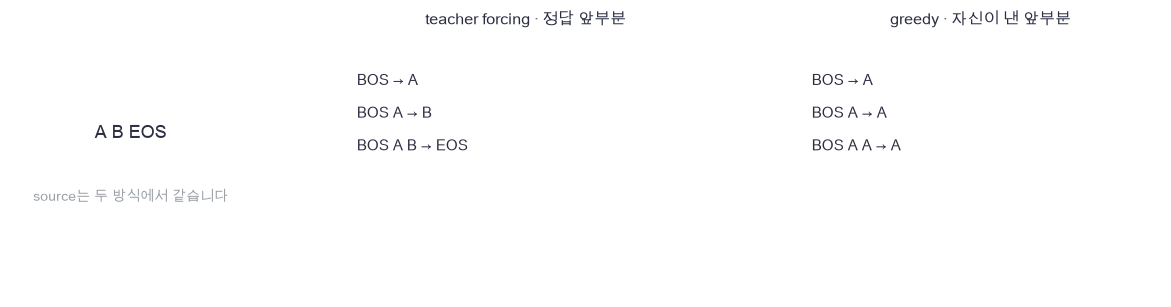

In [46]:
plot_generation_protocol("A B EOS", protocol_teacher_lines, protocol_free_lines)

🔍 **그림 확인과 평가 분모**

왼쪽 teacher prefix는 정답에서 오지만 오른쪽 prefix는 실제 모델 출력에서 옵니다. 한 번 다른 기호를 쓰면 그 뒤 조건도 달라집니다. 아래 학습 실험은 길이 1–4, 네 기호의 가능한 문자열 **340개**를 중복 없이 만든 뒤 seed로 섞어 train 240·validation 50·test 50으로 나눕니다. 길이·초기화·batch schedule·600스텝·학습률 .01은 test를 보기 전에 정합니다.

| 보고값 | 기준과 분모 |
|---|---|
| teacher CE·토큰 정확도 | 정답 prefix를 제공. EOS를 포함한 valid target 토큰 수 |
| free 토큰 정확도 | 생성 위치와 정답 위치 비교. **정답 기호+EOS의 전체 개수**를 분모로 고정 |
| free exact match | EOS를 포함한 생성 목록과 정답 목록이 길이·내용 모두 같은 표본 비율 |
| EOS 종료율 | 상한 안에서 실제 EOS를 내고 멈춘 표본 비율. 올바른 위치에서 멈췄다는 뜻은 아님 |
| 조기 EOS율 | 정답보다 짧은 생성 목록에서 EOS로 멈춘 표본 비율 |

free token 점수에서 생성하지 못한 남은 정답 위치는 모두 오답입니다. 긴 오답 출력도 exact match를 통과할 수 없습니다. 예를 들어 정답 `[A,B,EOS]`에 `[A,EOS]`를 내면 토큰 정확도는 $1/3$, exact는 0, EOS 종료는 1입니다. 이들을 한 점수로 섞지 않습니다.

In [47]:
# 쓰는 것: embedding_forward, encoder_forward, decoder_forward (3절), BOS, EOS, PAD (준비 셀)
def greedy_decode(source_ids, source_keep, params, max_new_tokens=7):
    """정답 없이 BOS에서 시작해 EOS 또는 고정 상한까지 실제로 이어 씁니다."""
    assert max_new_tokens >= 1, "생성 상한은 한 토큰 이상이어야 합니다"
    generated = []
    for n in range(len(source_ids)):
        # 1) 원문을 한 번 인코딩합니다. 이후에는 같은 기억을 다시 읽습니다.
        keep = source_keep[n:n+1]
        features, _ = embedding_forward(source_ids[n:n+1], params["src_embedding"], keep)
        memory, _ = encoder_forward(features, keep, params)
        prefix = [BOS]
        output = []
        # 2) 아직 정답 토큰은 어느 곳에서도 받지 않았습니다.
        for _ in range(max_new_tokens):
            ids = np.array([prefix], dtype=int)
            target_keep = np.ones_like(ids, dtype=bool)
            target_features, _ = embedding_forward(ids, params["tgt_embedding"], target_keep)
            logits, _ = decoder_forward(target_features, memory, keep, target_keep, params)
            scores = logits[0, -1].copy()
            scores[[PAD, BOS]] = -np.inf
            token = int(np.argmax(scores))
            output.append(token)
            if token == EOS:
                break
            prefix.append(token)
        generated.append(output)
    return generated

In [48]:
# 쓰는 것: EOS (준비 셀)
def free_generation_metrics(generated, references):
    """정답+EOS 길이 분모로 토큰 일치·전체 일치·종료를 따로 계산합니다."""
    assert len(generated) == len(references), "모든 평가 표본에 생성 결과가 있어야 합니다"
    correct = 0
    total = 0
    exact = 0
    ended = 0
    early = 0
    for prediction, tokens in zip(generated, references):
        reference = list(tokens) + [EOS]
        for position, truth in enumerate(reference):
            total += 1
            if position < len(prediction) and prediction[position] == truth:
                correct += 1
        exact += int(prediction == reference)
        has_eos = len(prediction) > 0 and prediction[-1] == EOS
        ended += int(has_eos)
        early += int(has_eos and len(prediction) < len(reference))
    count = len(references)
    return {"token_accuracy": correct / total, "exact_match": exact / count,
            "eos_rate": ended / count, "early_eos_rate": early / count, "reference_tokens": total}

In [49]:
# 쓰는 것: sequence_forward (3절), masked_cross_entropy (4절)
def teacher_metrics(packed, params):
    """정답 prefix에서 valid 토큰 CE와 정확도를 계산합니다."""
    source, decoder, target, source_keep, target_keep = packed
    logits, _ = sequence_forward(source, decoder, source_keep, target_keep, params)
    loss, _ = masked_cross_entropy(logits, target, target_keep)
    correct = (np.argmax(logits, axis=-1) == target) & target_keep
    accuracy = np.sum(correct) / np.sum(target_keep)
    return loss, float(accuracy)

In [50]:
# 쓰는 것: protocol_source, protocol_keep, protocol_params, protocol_generated (5절 설명 그림), EOS (준비 셀)
actual_protocol = greedy_decode(protocol_source, protocol_keep, protocol_params, max_new_tokens=3)
np.testing.assert_array_equal(actual_protocol[0], protocol_generated)  # 검산: encoder 기억을 재사용해도 설명 그림의 실제 생성과 같습니다.
early_metrics = free_generation_metrics([[3, EOS]], [(3, 4)])
np.testing.assert_allclose(early_metrics["token_accuracy"], 1/3)  # 검산: 조기 종료해도 정답의 세 위치를 분모에 넣습니다.
np.testing.assert_allclose([early_metrics["exact_match"], early_metrics["eos_rate"], early_metrics["early_eos_rate"]], [0., 1., 1.])  # 검산: 종료 성공과 내용 일치는 다른 지표입니다.
unfinished_metrics = free_generation_metrics([[3, 4]], [(3, 4)])
np.testing.assert_allclose(unfinished_metrics["token_accuracy"], 2/3)  # 검산: EOS를 내지 못한 마지막 자리도 오답입니다.
assert unfinished_metrics["eos_rate"] == 0, "상한에서 EOS를 덧붙이면 안 됩니다"
print("실제 greedy·조기 EOS·미종료의 평가 분모 검산 통과")

실제 greedy·조기 EOS·미종료의 평가 분모 검산 통과


📎 **열거와 분할에 쓰는 코드**

> **코드** · `product(symbols, repeat=L)`은 길이 L의 모든 기호 조합을 만듭니다. `set` 교집합이 비어 있는지 확인해 고유 sequence의 분할 누출을 검사합니다. `rng.integers(...,size=(스텝,배치))`는 고정 배치 계획을 미리 뽑으며 같은 표본을 다시 뽑을 수 있습니다. 사전 내포의 `.copy()`는 초기 배열과 학습 배열을 분리합니다.

In [51]:
# 고유 문자열의 분할과 학습 예산을 결과를 보기 전에 정합니다.
symbols = (3, 4, 5, 6)
all_sequences = []
for length in range(1, 5):
    all_sequences.extend(product(symbols, repeat=length))
split_order = np.random.default_rng(208).permutation(len(all_sequences))
train_sequences = [all_sequences[i] for i in split_order[:240]]
valid_sequences = [all_sequences[i] for i in split_order[240:290]]
test_sequences = [all_sequences[i] for i in split_order[290:]]
assert not set(train_sequences) & set(valid_sequences), "train과 validation 문자열이 겹치면 안 됩니다"
assert not set(train_sequences) & set(test_sequences), "train과 test 문자열이 겹치면 안 됩니다"
assert not set(valid_sequences) & set(test_sequences), "validation과 test 문자열이 겹치면 안 됩니다"
assert len(set(all_sequences)) == 340, "길이 1–4 네 기호 문자열은 총 340개입니다"
TRAIN_STEPS, TRAIN_BATCH, TRAIN_RATE = 600, 32, 0.01
batch_schedule = np.random.default_rng(209).integers(0, len(train_sequences), size=(TRAIN_STEPS, TRAIN_BATCH))
print("고유 sequence 분할:", len(train_sequences), len(valid_sequences), len(test_sequences))

고유 sequence 분할: 240 50 50


In [52]:
# 쓰는 것: pack_sequences (1절), init_sequence_model (3절), train_sequences, valid_sequences, test_sequences (5절 분할)
train_packed = pack_sequences(train_sequences, width=5)
valid_packed = pack_sequences(valid_sequences, width=5)
test_packed = pack_sequences(test_sequences, width=5)
initial_params = init_sequence_model(dimension=16, seed=210)
initial_snapshot = {name: values.copy() for name, values in initial_params.items()}
print("학습 파라미터 수:", sum(values.size for values in initial_params.values()))

학습 파라미터 수: 3415


📎 **학습 루프의 범위**

Adam은 배열마다 $m\leftarrow0.9m+0.1g$, $v\leftarrow0.999v+0.001g^2$를 누적하고, $\widehat m=m/(1-0.9^t)$, $\widehat v=v/(1-0.999^t)$로 보정해 $\theta\leftarrow\theta-0.01\widehat m/(\sqrt{\widehat v}+10^{-8})$로 갱신합니다. validation은 100스텝마다 기록하고, 기록을 보고 스텝 수나 설정을 고르지 않습니다. test는 학습 후에만 평가합니다.

In [53]:
def adam_step(params, gradients, moments, squares, step, learning_rate):
    """각 파라미터의 두 모멘트를 편향 보정해 Adam으로 갱신합니다."""
    for name in params:
        moments[name] = 0.9 * moments[name] + 0.1 * gradients[name]
        squares[name] = 0.999 * squares[name] + 0.001 * gradients[name] ** 2
        first = moments[name] / (1 - 0.9 ** step)
        second = squares[name] / (1 - 0.999 ** step)
        params[name] -= learning_rate * first / (np.sqrt(second) + 1e-8)

In [54]:
# 쓰는 것: sequence_forward, sequence_backward (3절), masked_cross_entropy (4절), teacher_metrics, adam_step (5절)
def train_sequence_model(initial, train_data, valid_data, schedule, learning_rate=0.01):
    """고정 배치 계획으로 실제 CE를 학습하고 마지막 모델을 반환합니다."""
    # 1) 초기 가중치와 optimizer 상태를 독립적으로 보관합니다.
    params = {name: values.copy() for name, values in initial.items()}
    moments = {name: np.zeros_like(values) for name, values in params.items()}
    squares = {name: np.zeros_like(values) for name, values in params.items()}
    history = []
    for step in range(len(schedule) + 1):
        if step % 100 == 0 or step == len(schedule):
            valid_loss, valid_accuracy = teacher_metrics(valid_data, params)
            history.append([step, valid_loss, valid_accuracy])
            print(f"step {step:3d}: validation CE={valid_loss:.4f}, teacher token acc={valid_accuracy:.3f}")
        if step == len(schedule):
            break
        # 2) 유효 target 평균 CE → 모든 attention·embedding 미분 → Adam입니다.
        index = schedule[step]
        source, decoder, target, source_keep, target_keep = [array[index] for array in train_data]
        logits, cache = sequence_forward(source, decoder, source_keep, target_keep, params)
        loss, dlogits = masked_cross_entropy(logits, target, target_keep)
        _, _, gradients = sequence_backward(dlogits, cache)
        assert np.isfinite(loss), "학습 손실은 유한해야 합니다"
        assert all(np.all(np.isfinite(g)) for g in gradients.values()), "모든 학습 기울기가 유한해야 합니다"
        adam_step(params, gradients, moments, squares, step + 1, learning_rate)
    return params, np.asarray(history)

In [55]:
# 쓰는 것: initial_params, initial_snapshot, train_packed, valid_packed, batch_schedule, TRAIN_RATE (5절)
training_started = perf_counter()
trained_params, sequence_history = train_sequence_model(initial_params, train_packed, valid_packed, batch_schedule, TRAIN_RATE)
for name in initial_params:
    np.testing.assert_array_equal(initial_params[name], initial_snapshot[name])  # 검산: 실제 학습이 미학습 기준선 배열을 바꾸지 않습니다.
print(f"학습 경과 시간: {perf_counter() - training_started:.1f}초")

step   0: validation CE=2.2645, teacher token acc=0.172


step 100: validation CE=0.0008, teacher token acc=1.000


step 200: validation CE=0.0002, teacher token acc=1.000


step 300: validation CE=0.0001, teacher token acc=1.000


step 400: validation CE=0.0001, teacher token acc=1.000


step 500: validation CE=0.0001, teacher token acc=1.000


step 600: validation CE=0.0000, teacher token acc=1.000
학습 경과 시간: 0.4초


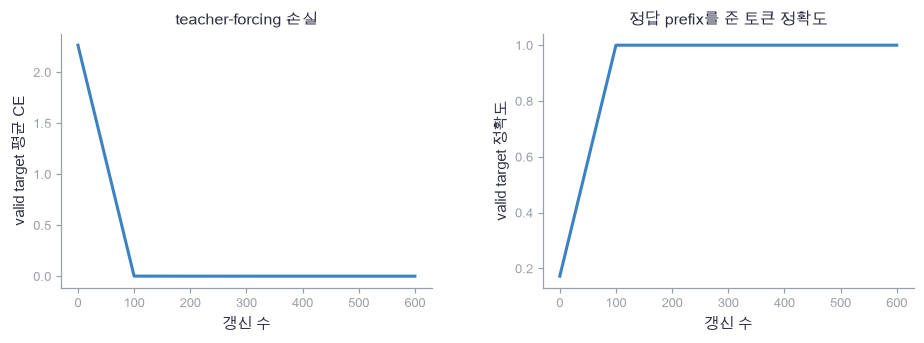

In [56]:
plot_sequence_history(sequence_history)

🔍 **학습 기록 확인**

곡선은 정답 prefix를 준 validation의 결과입니다. 정답이 다음 입력으로 주어지는 조건이므로 자유 생성과 구별합니다. 아래에서 같은 held-out 50개 문자열에 대한 미학습·학습 모델의 teacher 지표와 실제 자유 생성을 나란히 보고합니다. 높은 점수나 특정 향상 폭을 미리 보장하지 않습니다.

In [57]:
# 쓰는 것: teacher_metrics, greedy_decode, free_generation_metrics, test_packed, test_sequences, initial_params, trained_params (5절)
untrained_teacher = teacher_metrics(test_packed, initial_params)
trained_teacher = teacher_metrics(test_packed, trained_params)
untrained_generated = greedy_decode(test_packed[0], test_packed[3], initial_params)
trained_generated = greedy_decode(test_packed[0], test_packed[3], trained_params)
untrained_free = free_generation_metrics(untrained_generated, test_sequences)
trained_free = free_generation_metrics(trained_generated, test_sequences)
print("미학습 teacher (CE, token acc):", untrained_teacher)
print("학습 후 teacher (CE, token acc):", trained_teacher)
print("미학습 free:", untrained_free)
print("학습 후 free:", trained_free)

미학습 teacher (CE, token acc): (2.2493515186440645, 0.17647058823529413)
학습 후 teacher (CE, token acc): (3.326697163257134e-05, 1.0)
미학습 free: {'token_accuracy': 0.18487394957983194, 'exact_match': 0.0, 'eos_rate': 0.0, 'early_eos_rate': 0.0, 'reference_tokens': 238}
학습 후 free: {'token_accuracy': 1.0, 'exact_match': 1.0, 'eos_rate': 1.0, 'early_eos_rate': 0.0, 'reference_tokens': 238}


In [58]:
# 쓰는 것: TOKEN_NAMES, EOS (준비 셀), test_sequences, trained_generated (5절)
display_source_texts = [" ".join(TOKEN_NAMES[i] for i in sequence) for sequence in test_sequences[:6]]
display_reference_texts = [" ".join(TOKEN_NAMES[i] for i in list(sequence) + [EOS]) for sequence in test_sequences[:6]]
display_generated_texts = [" ".join(TOKEN_NAMES[i] for i in sequence) for sequence in trained_generated[:6]]

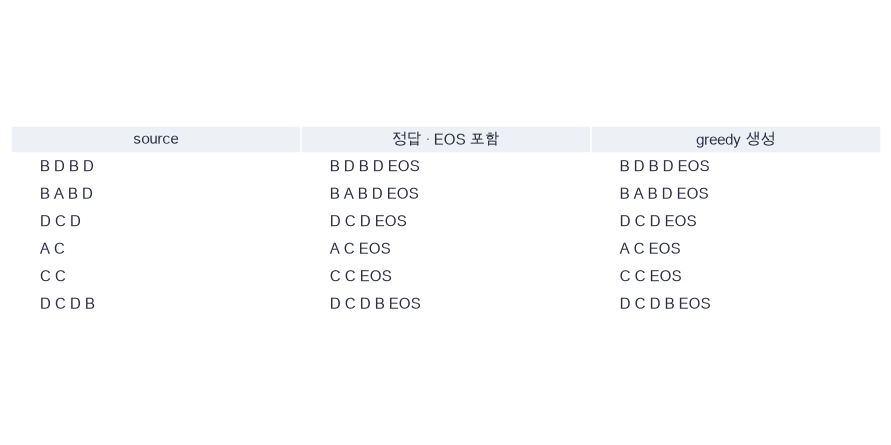

In [59]:
plot_generated_examples(display_source_texts, display_reference_texts, display_generated_texts)

🔍 **독립 생성과 길이 변형 확인**

표시는 점수를 보고 고른 예시가 아니라 미리 나눈 test의 첫 여섯 개입니다. 정답보다 먼저 EOS를 냈는지, 같은 기호를 반복했는지, 종료하지 못했는지 읽습니다. teacher와 free 정확도가 같게 나왔다면 이 실험에서 둘이 비슷했다는 뜻이며, 정의가 같은 지표라는 뜻은 아닙니다.

마지막으로 **내용은 그대로 두고 PAD 폭만 늘리는 검사**와 **학습하지 않은 길이 6의 별도 진단**을 나눕니다. 전자는 같은 계산이어야 하는 불변성입니다. 후자는 다른 문제 조건이라 성능이 달라질 수 있습니다. 둘 다 파라미터를 갱신하지 않습니다. 길이 6의 정답은 EOS까지 7토큰이므로 기존 생성 상한 7 안에 들어갑니다.

In [60]:
# 쓰는 것: pack_sequences (1절), sequence_forward (3절), greedy_decode, test_sequences, test_packed, trained_params, trained_generated (5절)
wider_test = pack_sequences(test_sequences[:6], width=8)
base_scores, _ = sequence_forward(test_packed[0][:6], test_packed[1][:6], test_packed[3][:6], test_packed[4][:6], trained_params)
wider_scores, _ = sequence_forward(wider_test[0], wider_test[1], wider_test[3], wider_test[4], trained_params)
np.testing.assert_allclose(wider_scores[:, :5], base_scores, atol=1e-10)  # 검산: 뒤에 PAD를 붙여도 기존 위치의 logit은 같습니다.
wider_generated = greedy_decode(wider_test[0], wider_test[3], trained_params)
assert wider_generated == trained_generated[:6], "같은 원문의 PAD 폭만 바꾸면 greedy 결과도 같아야 합니다"
print("학습된 모델의 PAD 폭·생성 불변성 검산 통과")

학습된 모델의 PAD 폭·생성 불변성 검산 통과


In [61]:
# 쓰는 것: pack_sequences (1절), greedy_decode, free_generation_metrics, trained_params (5절)
long_rng = np.random.default_rng(211)
long_sequences = [tuple(long_rng.integers(3, 7, size=6)) for _ in range(12)]
long_packed = pack_sequences(long_sequences)
long_snapshot = {name: values.copy() for name, values in trained_params.items()}
long_generated = greedy_decode(long_packed[0], long_packed[3], trained_params, max_new_tokens=7)
print("학습 밖 길이 6의 별도 진단:", free_generation_metrics(long_generated, long_sequences))
for name in trained_params:
    np.testing.assert_array_equal(trained_params[name], long_snapshot[name])  # 검산: 길이 변형 평가는 모델을 갱신하지 않습니다.

학습 밖 길이 6의 별도 진단: {'token_accuracy': 0.6071428571428571, 'exact_match': 0.0, 'eos_rate': 0.6666666666666666, 'early_eos_rate': 0.6666666666666666, 'reference_tokens': 84}


🔍 **실험의 한계**

이 결과는 네 기호·길이 1–4·한 초기화·한 분할의 복사 과제입니다. 번역이나 일반적인 긴 문장 생성의 품질을 보여 주지는 않습니다. 길이 6 진단의 실패는 mask나 backward 오류와 다를 수 있고, 통과도 임의 길이의 성공을 보장하지 않습니다. test나 길이 진단을 보고 설정을 바꾸면 그 자료는 개발에 사용한 자료가 됩니다. 최종 성능을 다시 확인하려면 별도의 고정 평가 계획이 필요합니다.

### ✏️ 연습 5 · 실제 greedy의 허용 토큰 고르기

`logits`는 어휘 점수 벡터입니다. PAD·BOS를 제외하고 가장 큰 점수의 ID를 고르는 두 줄을 채우세요. 점수 사본은 이미 만들었습니다.

In [62]:
def exercise_greedy_token(logits, pad, bos):
    """시작·빈칸 전용 기호를 제외한 greedy 토큰을 고릅니다."""
    scores = logits.copy()
    raise NotImplementedError
    return token

In [63]:
def check_greedy_token(candidate):
    """금지된 기호가 더 높은 점수여도 허용 기호를 고르는지 검사합니다."""
    logits = np.array([100., 99., 2., 3., 1.])
    assert candidate(logits, 0, 1) == 3, "PAD·BOS를 제외하면 ID3의 점수가 가장 큽니다"
    assert candidate(np.array([100., 99., 4., 3., 1.]), 0, 1) == 2, "EOS도 허용된 생성 후보입니다"
    np.testing.assert_array_equal(logits, [100., 99., 2., 3., 1.])  # 검산: 선택 규칙은 원래 점수 배열을 바꾸지 않습니다.
run_check(check_greedy_token, exercise_greedy_token)

☐ exercise_greedy_token: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
scores[[pad, bos]] = -np.inf
token = int(np.argmax(scores))
```

</details>

## ✏️ 전체 연결 연습 A–D

중복 lookup, cross mask, loss mask, EOS를 포함한 전체 일치를 작은 배열로 다시 확인합니다. 학습을 다시 실행할 필요는 없습니다.

### ✏️ 연습 A · 같은 embedding 행에 여러 번 더하기

`ids`는 `(N,T)`, `contribution`은 `(N,T,d)`입니다. 같은 ID의 기여가 누락되지 않도록 표 기울기에 누적하는 한 줄을 채우세요. 여기에는 PAD가 없습니다.

In [64]:
def exercise_embedding_sum(ids, contribution, vocab_size):
    """반복 ID를 포함한 모든 위치 기울기를 표의 같은 행에 합합니다."""
    table_gradient = np.zeros((vocab_size, contribution.shape[-1]))
    raise NotImplementedError
    return table_gradient

In [65]:
def check_embedding_sum(candidate):
    """ID1을 두 번 읽은 두 위치의 합을 손계산으로 검사합니다."""
    result = candidate(np.array([[1, 1, 2]]), np.array([[[1., 2.], [3., 4.], [5., 6.]]]), 3)
    np.testing.assert_array_equal(result, [[0., 0.], [4., 6.], [5., 6.]])  # 검산: ID1 행에는 [1,2]+[3,4]가 들어갑니다.
run_check(check_embedding_sum, exercise_embedding_sum)

☐ exercise_embedding_sum: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
np.add.at(table_gradient, ids, contribution)
```

</details>

### ✏️ 연습 B · cross의 행과 열 구분하기

`source_keep`은 `(N,S)`, `target_keep`은 `(N,T)`입니다. 출력 위치가 행, 원문 위치가 열인 cross mask 한 줄을 채우세요. 원문에는 미래 금지 삼각형을 적용하지 않습니다.

In [66]:
def exercise_cross_mask(source_keep, target_keep):
    """유효 decoder query와 유효 source key의 모든 쌍을 허용합니다."""
    raise NotImplementedError
    return mask

In [67]:
def check_cross_mask(candidate):
    """T=2,S=3인 직사각형에서 PAD 행·열을 검사합니다."""
    actual = candidate(np.array([[True, False, True]]), np.array([[True, False]]))
    np.testing.assert_array_equal(actual, [[[True, False, True], [False, False, False]]])  # 검산: 유효 query는 두 source key를 모두 읽을 수 있습니다.
run_check(check_cross_mask, exercise_cross_mask)

☐ exercise_cross_mask: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
mask = target_keep[:, :, None] & source_keep[:, None, :]
```

</details>

### ✏️ 연습 C · loss mask를 logit 기울기에도 적용하기

`difference`는 `probability-onehot(target)`이고 shape는 `(N,T,V)`입니다. valid mask와 유효 토큰 수를 반영한 한 줄을 채우세요.

In [68]:
def exercise_masked_ce_gradient(difference, valid):
    """PAD logit 기울기를 0으로 만들고 valid 토큰 수로 평균합니다."""
    raise NotImplementedError
    return gradient

In [69]:
def check_masked_ce_gradient(candidate):
    """유효 토큰 하나와 PAD 하나에서 분모와 0 기울기를 검사합니다."""
    result = candidate(np.array([[[0.25, -0.25], [-0.2, 0.2]]]), np.array([[True, False]]))
    np.testing.assert_allclose(result, [[[0.25, -0.25], [0., 0.]]])  # 검산: 분모는 1이고 PAD 행은 0입니다.
run_check(check_masked_ce_gradient, exercise_masked_ce_gradient)

☐ exercise_masked_ce_gradient: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
gradient = difference * valid[..., None] / np.sum(valid)
```

</details>

### ✏️ 연습 D · EOS까지 같은 전체 생성인지 확인하기

`prediction`과 `reference`는 Python 목록이며 reference에는 EOS가 포함됩니다. 길이와 모든 토큰이 같은지 판정하는 한 줄을 채우세요.

In [70]:
def exercise_exact_sequence(prediction, reference):
    """EOS를 포함한 두 생성 목록의 길이·내용 전체를 비교합니다."""
    raise NotImplementedError
    return exact

In [71]:
def check_exact_sequence(candidate):
    """정확한 종료·조기 종료·미종료·추가 토큰을 따로 검사합니다."""
    assert candidate([3, 4, 2], [3, 4, 2]), "EOS까지 같은 목록은 정확한 생성입니다"
    assert not candidate([3, 2], [3, 4, 2]), "조기 EOS는 전체 일치가 아닙니다"
    assert not candidate([3, 4], [3, 4, 2]), "EOS 미종료도 전체 일치가 아닙니다"
    assert not candidate([3, 4, 2, 5], [3, 4, 2]), "정답보다 긴 목록도 전체 일치가 아닙니다"
run_check(check_exact_sequence, exercise_exact_sequence)

☐ exercise_exact_sequence: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
exact = prediction == reference
```

</details>

## ✏️ 다음 단계 준비도

**설명 확인:** 09번의 고정 길이 한 번 예측과 이 노트북의 source/target 분리·한 토큰씩 생성은 무엇이 다른가요? BOS·EOS·PAD와 teacher forcing의 역할을 각각 설명할 수 있나요?

**수식 확인:** cross의 $(N,T,S)$ 확률에서 행과 열의 의미는 무엇인가요? encoder 기억에 K·V 기여가 더해지는 이유, decoder residual의 직접 기여, valid target 분모를 다시 유도할 수 있나요?

**구현 확인:** decoder causal mask에 key padding만이 아니라 query padding도 넣은 위치를 찾을 수 있나요? 반복 토큰의 embedding 기울기를 왜 누적해야 하나요? 생성 함수가 정답 target을 받지 않고 encoder 기억을 재사용하는지 확인할 수 있나요?

**변형 검산:** 미래 target을 바꿔도 과거 logit이 같은지, PAD 값을 바꿔도 결과가 같은지, 전부 막힌 attention 행이 0인지 검사할 수 있나요? 조기 EOS·미종료가 free 토큰 분모와 exact match에 어떻게 반영되는지 손으로 계산할 수 있나요? 길이 밖 성능과 padding 불변성을 구별할 수 있나요?

[19 ViT](19_vit.ipynb)의 패치 토큰과 [21 집합·그래프 attention](21_sets_graph_attention.ipynb)의 이웃 토큰으로 넘어가도 Q·K·V의 미분은 이어집니다. 달라지는 것은 입력의 의미, 순서·위치의 가정, 읽도록 허용한 관계입니다.